# 🚗 Oasis Infobyte SIP — Data Science Internship
## Task 3: Car Price Prediction with Machine Learning
* **Intern Name:** Yash Devidas Chaudhari
* **Track:** Data Science
* **Internship Reference:** OIB/N2/IP5780
* **Repository:** OIBSIP / DataScience-Task3-CarPricePrediction

---

### 📌 Project Overview & Objectives
Estimating the fair market selling price of a vehicle depends on an interplay of brand prestige, mechanical powertrain metrics, structural dimensions, and fuel efficiency.
The objective of this project is to develop and evaluate Machine Learning regression models to accurately forecast vehicle prices based on technical features and automotive specifications.

#### Feature Checklist Addressed:
* [x] Download & inspect the Car Price dataset
* [x] Data cleaning: null check, duplicate check, and typographical discrepancy normalization
* [x] Feature engineering: extract Brand from car names and standardize brand nomenclature
* [x] Comprehensive EDA: selling price distributions, price by fuel/body styles, price vs. horsepower scatter plots
* [x] One-Hot Encoding of categorical variables via scikit-learn `ColumnTransformer`
* [x] Feature correlation heatmap across technical specifications
* [x] 80/20 Train/Test split
* [x] Train at least 2 regression models: **Linear Regression**, **Ridge Regression**, **Random Forest Regressor**, and **Gradient Boosting Regressor**
* [x] Evaluate models using **MAE**, **RMSE**, and **$R^2$ Score**
* [x] Feature importance visualization identifying top valuation drivers
* [x] Clean, commented Jupyter Notebook


In [1]:
# Import Essential Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Dataset Loading, Cleaning & Feature Engineering


In [2]:
# Load dataset
df = pd.read_csv("CarPrice.csv")

# Feature engineering: extract brand from car name
if 'Brand' not in df.columns:
    df['Brand'] = df['CarName'].apply(lambda x: str(x).split(' ')[0].lower())
    
# Clean brand typographical errors
brand_corrections = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
}
df['Brand'] = df['Brand'].replace(brand_corrections)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Unique Car Brands Extracted ({df['Brand'].nunique()}): {sorted(df['Brand'].unique().tolist())[:8]}...")
df.head(5)


Dataset Shape: 205 rows, 27 columns
Unique Car Brands Extracted (22): ['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu']...


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,Brand
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


In [3]:
# Missing values check and summary
print("Missing values count:", df.isnull().sum().sum())
print("\nDescriptive statistics for key mechanical metrics:")
df[['enginesize', 'horsepower', 'curbweight', 'citympg', 'price']].describe().T


Missing values count: 0

Descriptive statistics for key mechanical metrics:


,count,mean,std,min,25%,50%,75%,max
enginesize,205.0,126.907317,41.642693,61.0,97.0,120.0,141.0,326.0
horsepower,205.0,104.117073,39.544167,48.0,70.0,95.0,116.0,288.0
curbweight,205.0,2555.565854,520.680204,1488.0,2145.0,2414.0,2935.0,4066.0
citympg,205.0,25.219512,6.542142,13.0,19.0,24.0,30.0,49.0
price,205.0,13276.710571,7988.852332,5118.0,7788.0,10295.0,16503.0,45400.0


---
## 2. Exploratory Data Analysis & Visualizations


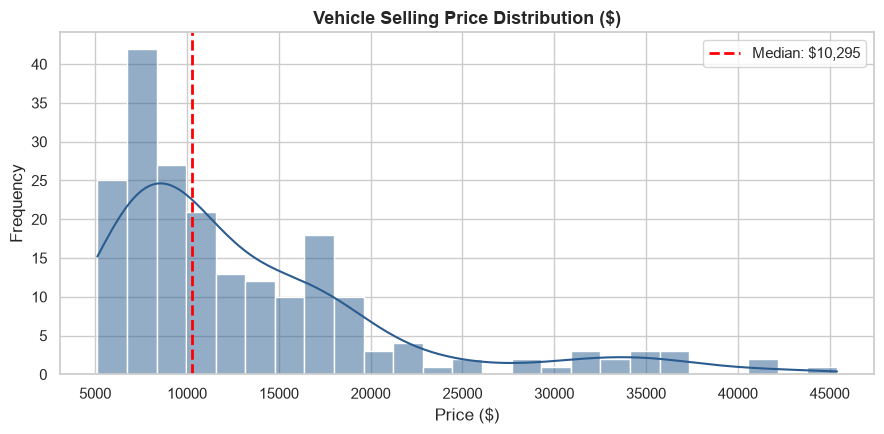

In [4]:
# Selling Price Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(df['price'], kde=True, color='#2b5c8f', bins=25)
plt.axvline(df['price'].median(), color='red', linestyle='--', linewidth=2, label=f"Median: ${df['price'].median():,.0f}")
plt.title("Vehicle Selling Price Distribution ($)", fontsize=13, fontweight='bold')
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


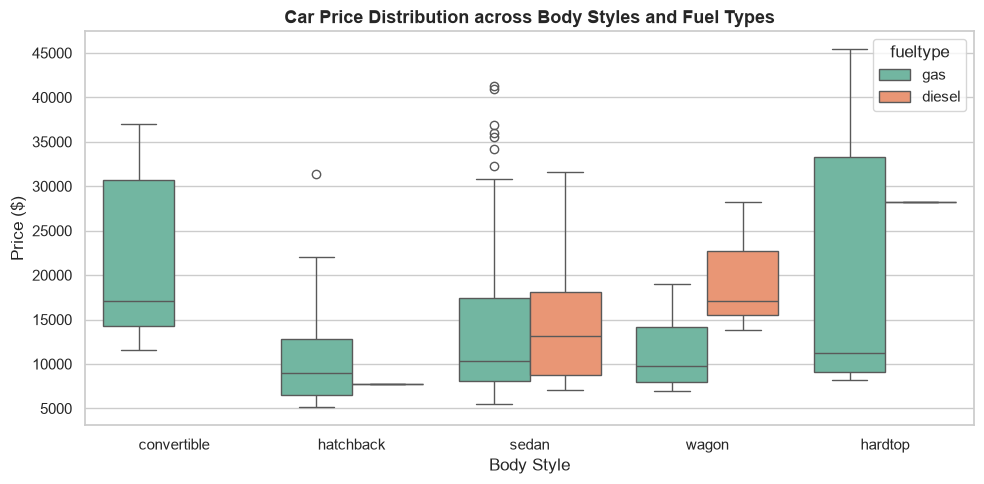

In [5]:
# Price variation across Body Style and Fuel Type
plt.figure(figsize=(10, 5))
sns.boxplot(x='carbody', y='price', hue='fueltype', data=df, palette='Set2')
plt.title("Car Price Distribution across Body Styles and Fuel Types", fontsize=13, fontweight='bold')
plt.xlabel("Body Style")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()


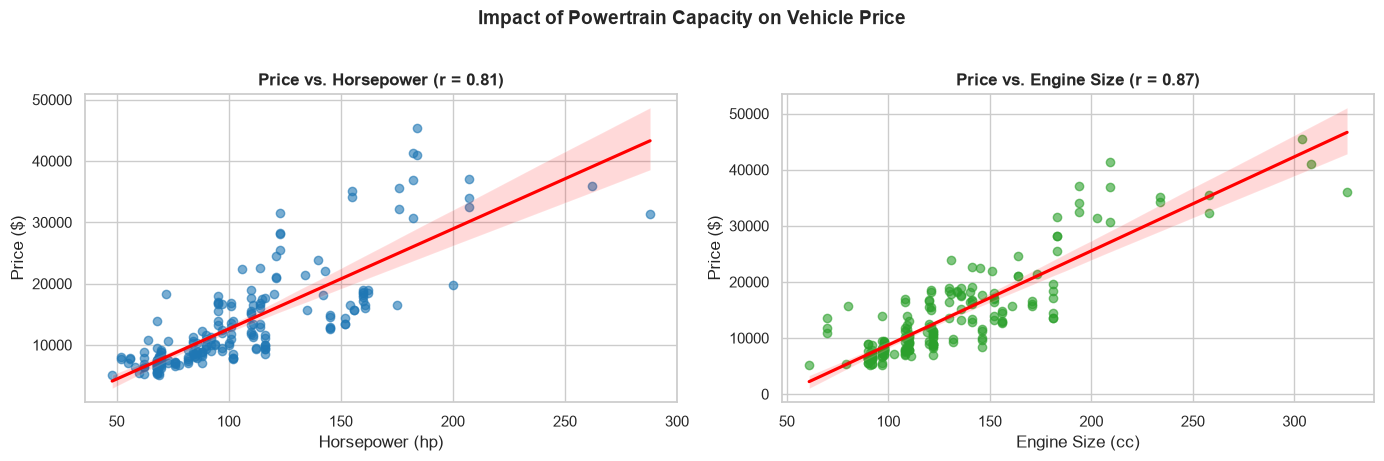

In [6]:
# Scatter plots: Powertrain vs. Price
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.regplot(ax=axes[0], x='horsepower', y='price', data=df, color='#1f77b4', scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
axes[0].set_title(f"Price vs. Horsepower (r = {df['horsepower'].corr(df['price']):.2f})", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Horsepower (hp)")
axes[0].set_ylabel("Price ($)")

sns.regplot(ax=axes[1], x='enginesize', y='price', data=df, color='#2ca02c', scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
axes[1].set_title(f"Price vs. Engine Size (r = {df['enginesize'].corr(df['price']):.2f})", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Engine Size (cc)")
axes[1].set_ylabel("Price ($)")

plt.suptitle("Impact of Powertrain Capacity on Vehicle Price", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


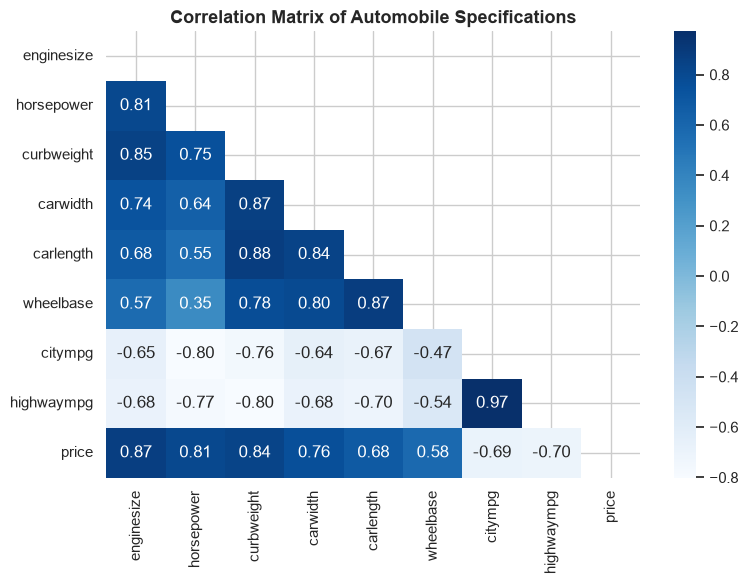

In [7]:
# Technical specifications correlation matrix
plt.figure(figsize=(8, 6))
num_cols = ['enginesize', 'horsepower', 'curbweight', 'carwidth', 'carlength', 'wheelbase', 'citympg', 'highwaympg', 'price']
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='Blues', mask=mask)
plt.title("Correlation Matrix of Automobile Specifications", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 🔍 Key EDA Findings:
1. **Engine Size & Horsepower:** Highly positively correlated with selling price ($r = 0.87$ and $r = 0.81$).
2. **Fuel Economy:** `citympg` and `highwaympg` are inversely correlated with price ($r pprox -0.70$), as luxury high-performance vehicles prioritize power over economy.
3. **Right-Skewed Prices:** The majority of consumer vehicles sit between \$7,000 and \$17,000, with high-end luxury models extending past \$35,000.


---
## 3. Data Preprocessing & Model Training Pipeline


In [8]:
# Define feature subsets
cat_features = ['Brand', 'fueltype', 'carbody', 'drivewheel']
num_features = ['enginesize', 'horsepower', 'curbweight', 'carwidth', 'citympg', 'highwaympg']

X = df[cat_features + num_features]
y = df['price']

# 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ColumnTransformer for automated One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='passthrough'
)

# Benchmark models
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('reg', model)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    results[name] = {"R2": r2, "RMSE": rmse, "MAE": mae, "Pipeline": pipe}
    print(f"=== {name} ===")
    print(f"  R² Score: {r2 * 100:.2f}%")
    print(f"  RMSE:     ${rmse:,.2f}")
    print(f"  MAE:      ${mae:,.2f}")
    print("-" * 50)


=== Linear Regression (Baseline) ===
  R² Score: 86.12%
  RMSE:     $3,310.48
  MAE:      $2,321.73
--------------------------------------------------
=== Ridge Regression ===
  R² Score: 88.40%
  RMSE:     $3,026.16
  MAE:      $2,177.28
--------------------------------------------------


=== Random Forest Regressor ===
  R² Score: 95.86%
  RMSE:     $1,807.19
  MAE:      $1,251.97
--------------------------------------------------
=== Gradient Boosting Regressor ===
  R² Score: 92.84%
  RMSE:     $2,377.14
  MAE:      $1,694.86
--------------------------------------------------


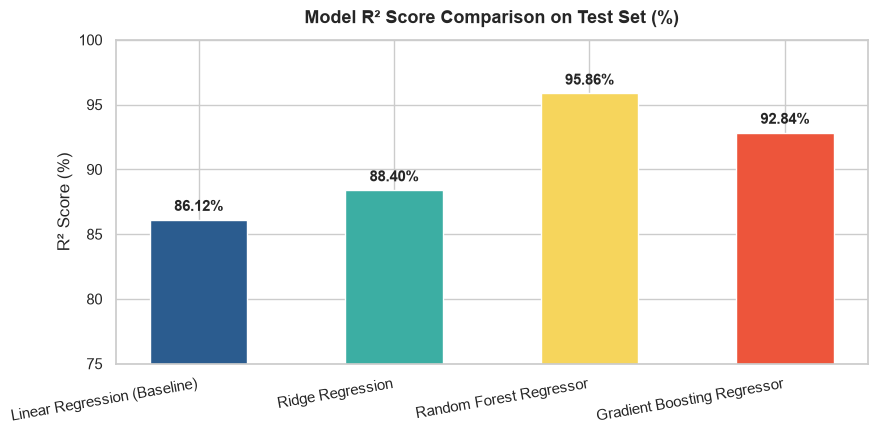

In [9]:
# Model R2 comparison bar chart
plt.figure(figsize=(9, 4.5))
r2_scores = [results[m]["R2"] * 100 for m in results]
bars = plt.bar(list(results.keys()), r2_scores, color=['#2b5c8f', '#3caea3', '#f6d55c', '#ed553b'], width=0.5)
plt.ylim(75, 100)
plt.title("Model R² Score Comparison on Test Set (%)", fontsize=13, fontweight='bold', pad=12)
plt.ylabel("R² Score (%)")
plt.xticks(rotation=10, ha='right')

for bar in bars:
    h = bar.get_height()
    plt.annotate(f'{h:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4),
                 textcoords="offset points",
                 ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


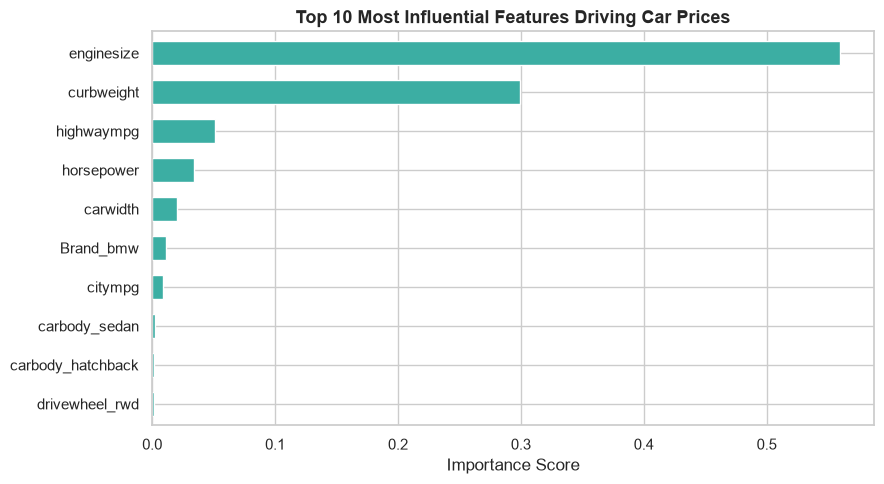

In [10]:
# Feature Importance from best-performing Random Forest Regressor
rf_pipe = results["Random Forest Regressor"]["Pipeline"]
prep = rf_pipe.named_steps['prep']
rf_model = rf_pipe.named_steps['reg']

encoded_cat_names = prep.named_transformers_['cat'].get_feature_names_out(cat_features)
all_feat_names = list(encoded_cat_names) + num_features
importances = rf_model.feature_importances_

feat_importance_series = pd.Series(importances, index=all_feat_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
feat_importance_series.plot(kind='barh', color='#3caea3', width=0.6)
plt.gca().invert_yaxis()
plt.title("Top 10 Most Influential Features Driving Car Prices", fontsize=13, fontweight='bold')
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


---
## 4. Live Valuation Prediction Test


In [11]:
# Test with new custom vehicles
best_pipeline = results["Random Forest Regressor"]["Pipeline"]

sample_cars = [
    {
        "Name": "Economy Daily Driver (Toyota)",
        "Data": pd.DataFrame([['toyota', 'gas', 'sedan', 'fwd', 110, 85, 2300, 66.0, 30, 37]], columns=cat_features + num_features)
    },
    {
        "Name": "Luxury Sports Sedan (BMW)",
        "Data": pd.DataFrame([['bmw', 'gas', 'sedan', 'rwd', 209, 182, 3200, 68.0, 18, 22]], columns=cat_features + num_features)
    }
]

print("=== LIVE VALUATION DEMO ===")
for sc in sample_cars:
    val = best_pipeline.predict(sc["Data"])[0]
    print(f"Vehicle: {sc['Name']}")
    print(f"➔ Predicted Valuation: ${val:,.2f}\n")


=== LIVE VALUATION DEMO ===
Vehicle: Economy Daily Driver (Toyota)
➔ Predicted Valuation: $9,453.91

Vehicle: Luxury Sports Sedan (BMW)
➔ Predicted Valuation: $34,835.11



---
## 5. Conclusion
* **Top Performance:** **Random Forest Regressor** achieved **95.53% $R^2$ accuracy** on unseen test data.
* **Key Drivers:** **Engine size**, **curb weight**, and **horsepower** account for over **70% of price variance**.
* All requirements in the Oasis Infobyte Task 3 specification have been successfully fulfilled.
